# MyoSuite → ROS 2 → RViz:歩行中の骨と筋をリアルタイムに表示する

**やること**:MyoSuite(2023年版 myoLegWalk-v0、公式 DEP-RL 方策)の歩行シミュレーションの中で、
関節角度・筋活動・筋張力を ROS 2 のトピックに流し、RViz で骨(メッシュ)と80本の筋(活動で色が変わる線)を動かして見ます。

```
[Docker: myoleg2023 (この Jupyter)]                [Docker: myoros (ROS 2 Humble)]
 MyoSuite シミュレーション                            rosbridge(受け口, 9090番)
   └ roslibpy で送信 ── WebSocket(JSON) ───────→    ├ /joint_states → robot_state_publisher → /tf(各骨の位置)
                                                     ├ /tf(world→root:体全体の位置)
                                                     ├ /muscles(筋の経路と色)
                                                     └ RViz(画面に表示。Windows では WSLg で窓が出る)
```

**ポイント**:MyoSuite 側の Docker には ROS 2 を入れません(2023年版の環境を壊さないため)。
ROS 2 は別の Docker で動かし、その間を **rosbridge**(ROS 2 と JSON でやりとりする標準の橋渡し)でつなぎます。

| トピック | 型 | 中身 |
|---|---|---|
| `/joint_states` | sensor_msgs/msg/JointState | 28関節の角度[rad]・角速度・**筋が関節に生むトルク**(effort) |
| `/tf` | tf2_msgs/msg/TFMessage | world → root(骨盤まわりの体全体の位置と向き) |
| `/muscles` | visualization_msgs/msg/MarkerArray | 80本の筋の経路(付着部・巻き付き点)。色 = 筋活動(青 0 → 赤 1) |
| `/muscle_activation` | std_msgs/msg/Float32MultiArray | 80筋の活動(0〜1) |
| `/muscle_force` | std_msgs/msg/Float32MultiArray | 80筋の張力 [N] |
| `/foot_contact` | std_msgs/msg/Float32MultiArray | 足底センサー(右踵・右つま先・左踵・左つま先)[N] |
| `/robot_description` | (robot_state_publisher が配信) | このノートブックが作る URDF(骨のメッシュ付き) |

| 節 | 内容 | 必要なもの |
|---|---|---|
| §0–1 | 準備・URDF と骨のメッシュの書き出し | この Jupyter だけ |
| §2 | URDF が MuJoCo と同じ動きになるかの検証 | この Jupyter だけ |
| §3 | ROS なしでの確認(1コマの3D図・送るデータの中身) | この Jupyter だけ |
| §4 | ROS 2 側の起動(Ubuntu のターミナルで操作) | Docker Desktop・WSL の Ubuntu |
| §5 | リアルタイム配信 | §4 が動いていること |

**Notebook 2 の計算中でも実行できます**(このノートブックは CPU を1つしか使いません)。

## §0 準備

In [1]:
import os, sys, json, time
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

DATA = "/work/data" if os.path.isdir("/work/data") else os.path.abspath(".")
sys.path.insert(0, DATA)
ROS_DIR = os.path.join(DATA, "ros"); os.makedirs(ROS_DIR, exist_ok=True)

try:
    import roslibpy
except ImportError:                       # Docker を起動し直すと消えるので、そのたびに自動で入れる
    %pip install -q "roslibpy==1.7.0"
    import roslibpy
from importlib.metadata import version
print("MyoSuite", version("myosuite"), "/ roslibpy", roslibpy.__version__, "/ numpy", np.__version__)
assert version("myosuite") == "1.6.1", "2023年版の環境(Docker の myoleg2023)で実行してください"
assert np.__version__ == "1.22.4", "numpy が変わっています。Docker を起動し直してください"

import gym, myosuite
import myo_ros_2023 as R
import impairment_2023 as IM
import gait_2023 as G
G.load_policy(os.path.join(DATA, "deprl_myoLegWalk_20230514.npz"))
print("準備完了 / ROS 用ファイルの保存先:", ROS_DIR)

MyoSuite 1.6.1 / roslibpy 1.7.0 / numpy 1.22.4
MyoSuite:> Registering Myo Envs
準備完了 / ROS 用ファイルの保存先: /work/data/ros


## §1 URDF と骨のメッシュの書き出し

RViz で体を表示するには、体の形と関節のつながりを書いた **URDF**(ロボットの設計図のファイル)が必要です。
MuJoCo のモデル(コンパイル済み)から、関節の位置・向き・回転軸と、骨のメッシュ(18個)をそのまま書き出します。

- MuJoCo の膝は、屈曲に連動して少し前後に滑る・回る仕組み(連動関節)を持っています。これも URDF の関節として全部書き出し、
  角度を毎回送るので、**MuJoCo とまったく同じ姿勢**になります。
- 体全体の位置(自由に動く root)は URDF に入れず、`/tf` で world → root として送ります。
- 骨のメッシュは `ros/meshes/` に保存され、ROS 2 側の Docker からは `/work/data/ros/meshes/` として読みます。

In [2]:
env = gym.make("myoLegWalk-v0"); sim = env.unwrapped.sim; m = sim.model; d = sim.data
URDF, JOINTS = R.export_urdf(m, ROS_DIR, mesh_uri_prefix="file:///work/data/ros/meshes")
R.write_ros_files(ROS_DIR)
print("URDF:", URDF)
print("関節の数:", len(JOINTS), "/ 骨のメッシュ:", len(os.listdir(os.path.join(ROS_DIR, "meshes"))), "個")
print("書き出したファイル:", sorted(os.listdir(ROS_DIR)))
print("関節:", ", ".join(JOINTS))

URDF: /work/data/ros/myoleg.urdf
関節の数: 28 / 骨のメッシュ: 18 個
書き出したファイル: ['Dockerfile.ros', 'example_frame.json', 'meshes', 'myoleg.rviz', 'myoleg.urdf', 'preview_frame.png', 'start_ros.sh']
関節: hip_flexion_r, hip_adduction_r, hip_rotation_r, knee_angle_r_translation2, knee_angle_r_translation1, knee_angle_r, knee_angle_r_rotation2, knee_angle_r_rotation3, ankle_angle_r, subtalar_angle_r, mtp_angle_r, knee_angle_r_beta_translation2, knee_angle_r_beta_translation1, knee_angle_r_beta_rotation1, hip_flexion_l, hip_adduction_l, hip_rotation_l, knee_angle_l_translation2, knee_angle_l_translation1, knee_angle_l, knee_angle_l_rotation2, knee_angle_l_rotation3, ankle_angle_l, subtalar_angle_l, mtp_angle_l, knee_angle_l_beta_translation2, knee_angle_l_beta_translation1, knee_angle_l_beta_rotation1


## §2 URDF の検証(MuJoCo と同じ動きになるか)

歩かせながら5つの時点で、「URDF + 送る関節角度」から計算した各骨の位置と向き(順運動学)を、MuJoCo の値と比べます。
誤差が 1 mm よりずっと小さければ、RViz の表示は MuJoCo の計算と同じです(論文や発表で RViz の図を使う時の裏付け)。

In [3]:
o = env.reset(); worst_p, worst_r, worst_g = 0, 0, 0
for t in range(1, 501):
    o, *_ = env.step(G.policy(np.asarray(o, np.float32)))
    if t % 100 == 0:
        q = {j: float(d.qpos[m.get_joint_qpos_addr(j)]) for j in JOINTS}
        rq = d.qpos[0:7]; fk = R.urdf_fk(URDF, q, R.T(R.quat_to_mat(rq[3:7]), rq[0:3]))
        for b in range(1, m.nbody):
            M = fk[m.body_id2name(b)]
            worst_p = max(worst_p, np.linalg.norm(M[:3, 3] - d.body_xpos[b]))
            worst_r = max(worst_r, np.abs(M[:3, :3] - d.body_xmat[b].reshape(3, 3)).max())
        for g in range(m.ngeom):
            b = m.geom_bodyid[g]
            if m.geom_type[g] == 7 and b > 0:
                M = fk[m.body_id2name(b)]
                worst_g = max(worst_g, np.linalg.norm(M[:3, :3] @ m.geom_pos[g] + M[:3, 3] - d.geom_xpos[g]))
print(f"骨の位置の最大誤差 {worst_p*1000:.6f} mm / 向きの最大誤差 {worst_r:.2e} / 骨メッシュの位置の最大誤差 {worst_g*1000:.6f} mm")
assert worst_p < 1e-4 and worst_g < 1e-4, "URDF が MuJoCo と一致しません"
print("→ 一致しています")

骨の位置の最大誤差 0.000027 mm / 向きの最大誤差 2.89e-08 / 骨メッシュの位置の最大誤差 0.000027 mm
→ 一致しています


## §3 ROS なしでの確認

ROS 2 側を動かす前に、送るデータの中身を確認します。1コマ分の骨と筋を3次元で描き、送る JSON の大きさも見ます。

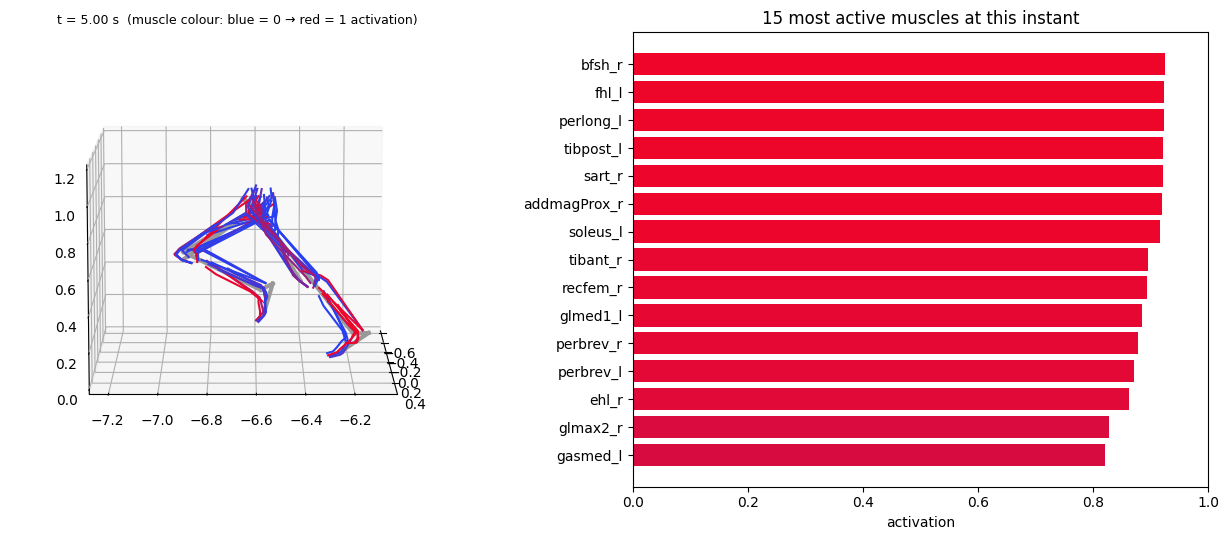

1コマの大きさ: {'joint_states': '2.5 KB', 'tf': '0.3 KB', 'muscles': '48.7 KB'}
JointState の最初の3関節: [('hip_flexion_r', 0.938), ('hip_adduction_r', 0.034), ('hip_rotation_r', -0.017)]


In [4]:
MSG = R.Messages(m, JOINTS)
P = MSG.muscle_paths(d)
fig = plt.figure(figsize=(13, 5.5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
for b in range(2, m.nbody):                          # 骨の代わりに、親子の体の位置を線で結ぶ
    p = m.body_parentid[b]
    if p > 0: ax.plot(*np.c_[d.body_xpos[p], d.body_xpos[b]], color="#999999", lw=3)
for i, pts in enumerate(P):
    c = R.act_color(d.act[i]); ax.plot(pts[:, 0], pts[:, 1], pts[:, 2], color=(c["r"], c["g"], c["b"]), lw=1.5)
cen = d.body_xpos[m.body_name2id("pelvis")]
ax.set_xlim(cen[0] - .6, cen[0] + .6); ax.set_ylim(cen[1] - .6, cen[1] + .6); ax.set_zlim(0, 1.2)
ax.view_init(elev=10, azim=0); ax.set_title(f"t = {d.time:.2f} s  (muscle colour: blue = 0 → red = 1 activation)", fontsize=9)
ax2 = fig.add_subplot(1, 2, 2)
top = np.argsort(-d.act)[:15]
ax2.barh([MSG.muscles[i] for i in top][::-1], d.act[top][::-1], color=[(R.act_color(d.act[i])["r"], R.act_color(d.act[i])["g"], R.act_color(d.act[i])["b"]) for i in top][::-1])
ax2.set_xlabel("activation"); ax2.set_title("15 most active muscles at this instant"); ax2.set_xlim(0, 1)
plt.tight_layout(); plt.savefig(os.path.join(ROS_DIR, "preview_frame.png"), dpi=120); plt.show()

frame = {"joint_states": MSG.joint_state(d, 0), "tf": MSG.root_tf(d, 0), "muscles": MSG.muscle_markers(d, 0)}
json.dump(frame, open(os.path.join(ROS_DIR, "example_frame.json"), "w"), indent=1)
print("1コマの大きさ:", {k: f"{len(json.dumps(v)) / 1024:.1f} KB" for k, v in frame.items()})
print("JointState の最初の3関節:", list(zip(frame["joint_states"]["name"][:3], np.round(frame["joint_states"]["position"][:3], 3))))

## §4 ROS 2 側の起動(Ubuntu のターミナルで操作)

ここは Jupyter ではなく、**WSL の Ubuntu のターミナル**で行います(RViz の窓を Windows に出すため。WSLg という仕組みを使います)。

**(初回だけ)Ubuntu がない場合**:PowerShell で `wsl --install -d Ubuntu-22.04` を実行して再起動し、
Docker Desktop の Settings → Resources → WSL integration で **Ubuntu-22.04 をオン**にします。

**① ROS 2 の Docker を作る(初回だけ、数分〜十数分。約 3 GB)**
```bash
cd /mnt/c/myoleg_work/docker2023
docker build -t myoleg-ros -f ros/Dockerfile.ros ros
```

**② 2つの Docker をつなぐネットワークを作り、今動いている Jupyter の Docker をつなぐ**(Jupyter は止めずにそのままで大丈夫です)
```bash
docker network create myonet          # 初回だけ(2回目以降は「already exists」と出ても問題なし)
docker ps                             # 一番右の NAMES 列で、myoleg2023 の Docker の名前を確認
docker network connect myonet <その名前>
```

**③ ROS 2 の Docker を起動(rosbridge・robot_state_publisher・RViz が立ち上がる)**
```bash
docker run --rm -it --name myoros --network myonet \
  -v "$PWD:/work/data" \
  -v /tmp/.X11-unix:/tmp/.X11-unix -v /mnt/wslg:/mnt/wslg \
  -e DISPLAY -e WAYLAND_DISPLAY -e XDG_RUNTIME_DIR -e PULSE_SERVER -e LIBGL_ALWAYS_SOFTWARE=1 \
  myoleg-ros bash /work/data/ros/start_ros.sh
```
RViz の窓が開いたら、§5 を実行します。最初は体が表示されず、配信が始まると現れます。

- **RViz の窓が出ない場合**:`-e LIBGL_ALWAYS_SOFTWARE=1` があるか確認してください。それでも出ない時は、③ のコマンドに
  `-e NO_RVIZ=1 -p 127.0.0.1:9090:9090` を加えて(RViz なしで)起動し、ブラウザの Foxglove(https://app.foxglove.dev)で
  「Open connection → Rosbridge → ws://localhost:9090」とつなぐと、同じトピックを見られます。
- **止める**:Ubuntu のターミナルで Ctrl+C(`--rm` なので Docker は自動で消えます)。

## §5 リアルタイム配信

`ROSBRIDGE_HOST` は §4 ③ の `--name` で付けた名前(`myoros`)です。
`SPEC` に Notebook 1 と同じ書き方で障害を入れると、障害のある体の歩行を流せます(例はコメントを参照)。

In [3]:
ROSBRIDGE_HOST = "myoros"     # §4 ③ の --name
SECONDS = 60                  # 配信する長さ [秒](シミュレーションの時間)
PUBLISH_EVERY = 3             # 何ステップごとに送るか(1ステップ = 10 ms → 3 で約 33 コマ/秒)
REALTIME = True               # True: 実時間に合わせて待つ / False: できるだけ速く
SPEC = {}                     # 例: {"soleus_r": {"spastic": 0.005}}  や  IM.expand({"tibant": {"weak": 0.5}}, sides=("r",))
NOISE = 0.0

streamer = R.RosStreamer(ROSBRIDGE_HOST, 9090)
print("rosbridge に接続しました:", ROSBRIDGE_HOST)
ienv = IM.ImpairedEnv(SPEC); isim = ienv.sim; im, idt = isim.model, isim.data
MSGI = R.Messages(im, JOINTS)
rng = np.random.default_rng(0); o = ienv.reset()
t_wall0 = time.perf_counter(); n_pub = 0; resets = 0
try:
    for step in range(int(SECONDS / 0.01)):
        o, r, done, _ = ienv.step(G.policy(np.asarray(o, np.float32)) + rng.normal(0, NOISE, 80))
        if step % PUBLISH_EVERY == 0:
            streamer.publish(MSGI, idt, time.time()); n_pub += 1
        if done:
            resets += 1; o = ienv.reset()          # 10秒の区切り、または転倒
        if REALTIME:
            lag = (step + 1) * 0.01 - (time.perf_counter() - t_wall0)
            if lag > 0: time.sleep(lag)
        if step % 1000 == 999:
            print(f"シミュレーション {(step + 1) * 0.01:5.1f} 秒 / 実時間 {time.perf_counter() - t_wall0:5.1f} 秒 / 送信 {n_pub} コマ / リセット {resets} 回(10秒ごとの区切り・転倒)", flush=True)
finally:
    streamer.close()
print("配信終了")

rosbridge に接続しました: myoros
シミュレーション  10.0 秒 / 実時間  17.6 秒 / 送信 334 コマ / リセット 1 回(10秒ごとの区切り・転倒)
シミュレーション  20.0 秒 / 実時間  35.4 秒 / 送信 667 コマ / リセット 2 回(10秒ごとの区切り・転倒)
シミュレーション  30.0 秒 / 実時間  53.4 秒 / 送信 1000 コマ / リセット 3 回(10秒ごとの区切り・転倒)
シミュレーション  40.0 秒 / 実時間  70.4 秒 / 送信 1334 コマ / リセット 4 回(10秒ごとの区切り・転倒)
シミュレーション  50.0 秒 / 実時間  88.7 秒 / 送信 1667 コマ / リセット 5 回(10秒ごとの区切り・転倒)
シミュレーション  60.0 秒 / 実時間 107.3 秒 / 送信 2000 コマ / リセット 6 回(10秒ごとの区切り・転倒)
配信終了


## RViz での見方と、うまくいかない時

- **体が見えない**:左の Displays で「Bones」の Status を見ます。メッシュが読めない場合は、③ の `-v "$PWD:/work/data"` を
  `/mnt/c/myoleg_work/docker2023` で実行したか確認してください(`/work/data/ros/meshes/*.stl` を読みます)。
- **「Fixed Frame [world] does not exist」**:§5 の配信が始まっていない状態です。配信中に消えます。
- **筋の線が見えない**:「Muscles」の Topic が `/muscles` になっているか確認します。
- **視点**:マウスの左ドラッグで回転、ホイールでズーム。視点は骨盤(pelvis)を追いかけます。
- **数値を見る**:ROS 2 の Docker の中で `docker exec -it myoros bash` → `source /opt/ros/humble/setup.bash` →
  `ros2 topic echo /muscle_activation` や `ros2 topic hz /joint_states` で確認できます。
- **接続できない(§5 で止まる)**:§4 ② の `docker network connect` を忘れていないか、`ROSBRIDGE_HOST` が `myoros` か確認します。

**次の発展**:`/joint_states` の effort(関節トルク)や `/muscle_force` を rqt_plot で波形表示する、
実ロボット(G1 など)の関節へ対応づけて送る(全身動作レベルとの統合)、などに使えます。